# Pearson, Spearman and mutual information — 2026-10-16

Fix $\beta=\pi$ and compare three channel constructions, with 50 independent MTS instances each. These 150 recordings come from the completed September focused extraction (pyspi computation r7); no new extraction is implied. Beta is an input choice, not an analysis axis.

Follow one mixed recording from its shared mother and channel construction, through individual edges and SPI matrices, to the SPI–SPI plane. Then check the pattern across independent recordings and quantify the effect of mixing pair types.

In [1]:
from pathlib import Path
import sys, json
import matplotlib.pyplot as plt
ROOT = Path.cwd().resolve()
while not (ROOT / 'src').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from research.cases.refresh_case_figures import (
    analyze, plot_pair_rainclouds, plot_rmi_channel_pairs,
    plot_mi_sensitivity, plot_spi_planes, plot_dtw_pair_sweep,
)
DATA = ROOT / 'data/cases/r-rho-mi-260924/data'
OUT = ROOT / 'results/cases/r-rho-mi-261016'
# Reanalyse the archived focused SPIs; do not recompute or mix computation versions.
frame = analyze(DATA, 'r-rho-mi', OUT)
audit = json.loads((OUT / 'audit.json').read_text())
BETA_TAG = 'beta-pi'
frame = frame[(frame.beta_tag == BETA_TAG) | (frame['class'] == 'iter1_L')].copy()
assert len(frame) == 150
frame.to_csv(OUT / 'selected-inputs.csv', index=False)
print(f"{len(frame)} selected recordings; 50 per mixture; beta=pi; {audit['nonfinite_off_diagonal_values']} nonfinite off-diagonal values in the archived bank")
from research.cases.case_mechanisms import (plot_rmi_construction, plot_rmi_matrices, analyze_rmi_composition, plot_rmi_composition)

150 selected recordings; 50 per mixture; beta=pi; 0 nonfinite off-diagonal values in the archived bank


Construction: one AR(1) mother, $s_t=0.8s_{t-1}+\epsilon_t$, is standardised to $u_t$. Channels observe $g(u)=u$ (L), $g(u)=1/(1+e^{-\beta u})$ (M), or $g(u)=u^2$ (Q). Each transformed signal is standardised before independent Gaussian measurement noise, and again afterwards. Noise standard deviations are $0.01\,\kappa_i$, with $\kappa_i\sim\mathrm{Geom}(1/5)$. This variation supplies a nonconstant profile of pair strengths; equal clean signal variance does not make estimation equally easy for every transform.

The channel counts (L,M,Q) are (32,0,0), (16,16,0), and (12,12,8), with $T=2000$ and $\beta=\pi$. The three mixtures use independent seeds. These existing data remain useful; a future construction need not use this large M or T.

The fixed example below is instance 0 of the L/M/Q mixture at $\beta=\pi$. A common window, samples 100–249, shows the mother and all 32 observed channels; heatmap colours saturate outside ±3 SD. Family boundaries follow the generating channel order. Replaying the stored seed must reproduce the archived observation within floating-point tolerance before the mother is displayed.

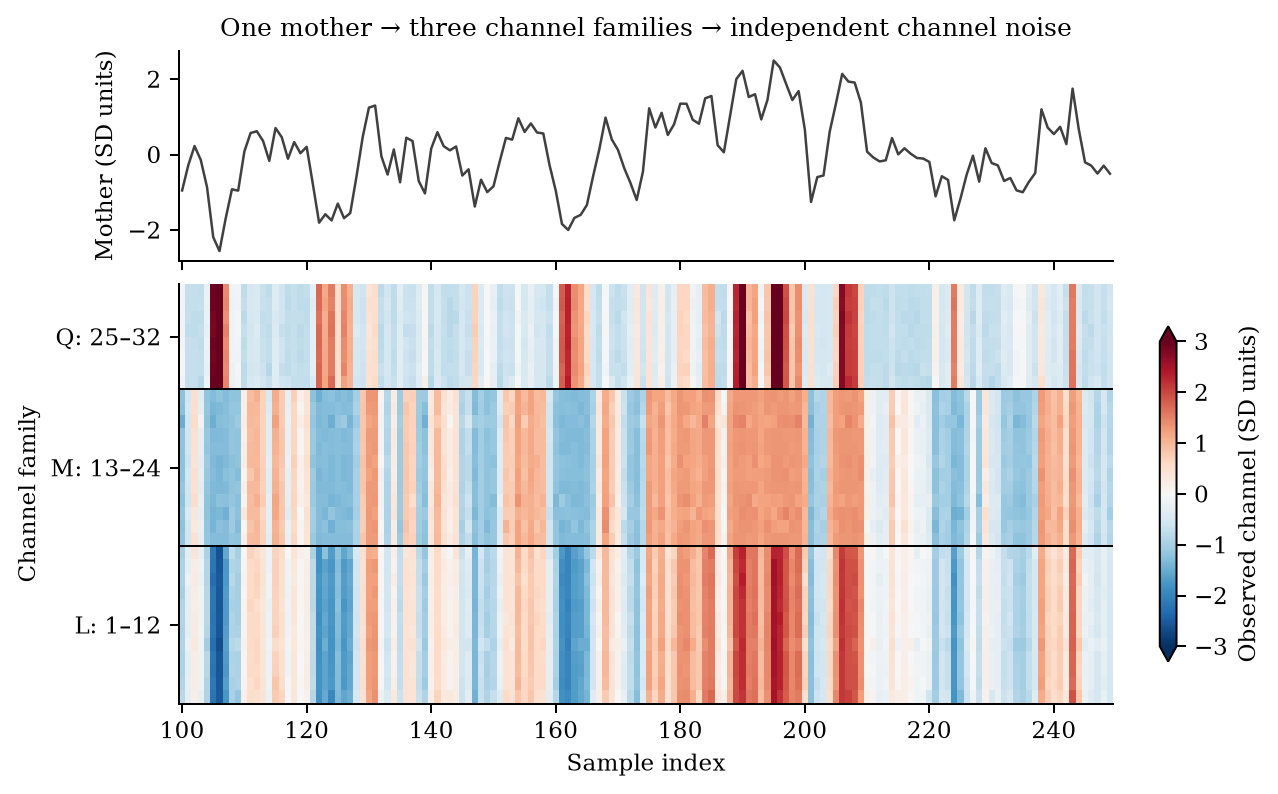

In [2]:
fig = plot_rmi_construction(frame, OUT, beta_tag=BETA_TAG)
plt.show()

The mechanism is visible in raw channel pairs. Pearson measures linear association without requiring Gaussian data; Spearman correlates ranks and is invariant to strictly increasing noiseless transforms. Noise and sigmoid saturation can still change ranks. The quadratic transform folds the relationship and can leave MI detectable while signed linear/rank correlations are small. The examples below are fixed in advance: instance 0, $\beta=\pi$, first linear channel against the next linear channel and the first channels of each other family. Values are the archived estimates, with MI in nats.

Edges A, B and C are channels 1–2 (L–L), 1–13 (L–M), and 1–25 (L–Q). These same edges are labelled in the matrix and SPI–SPI views, avoiding a change of example between explanations.

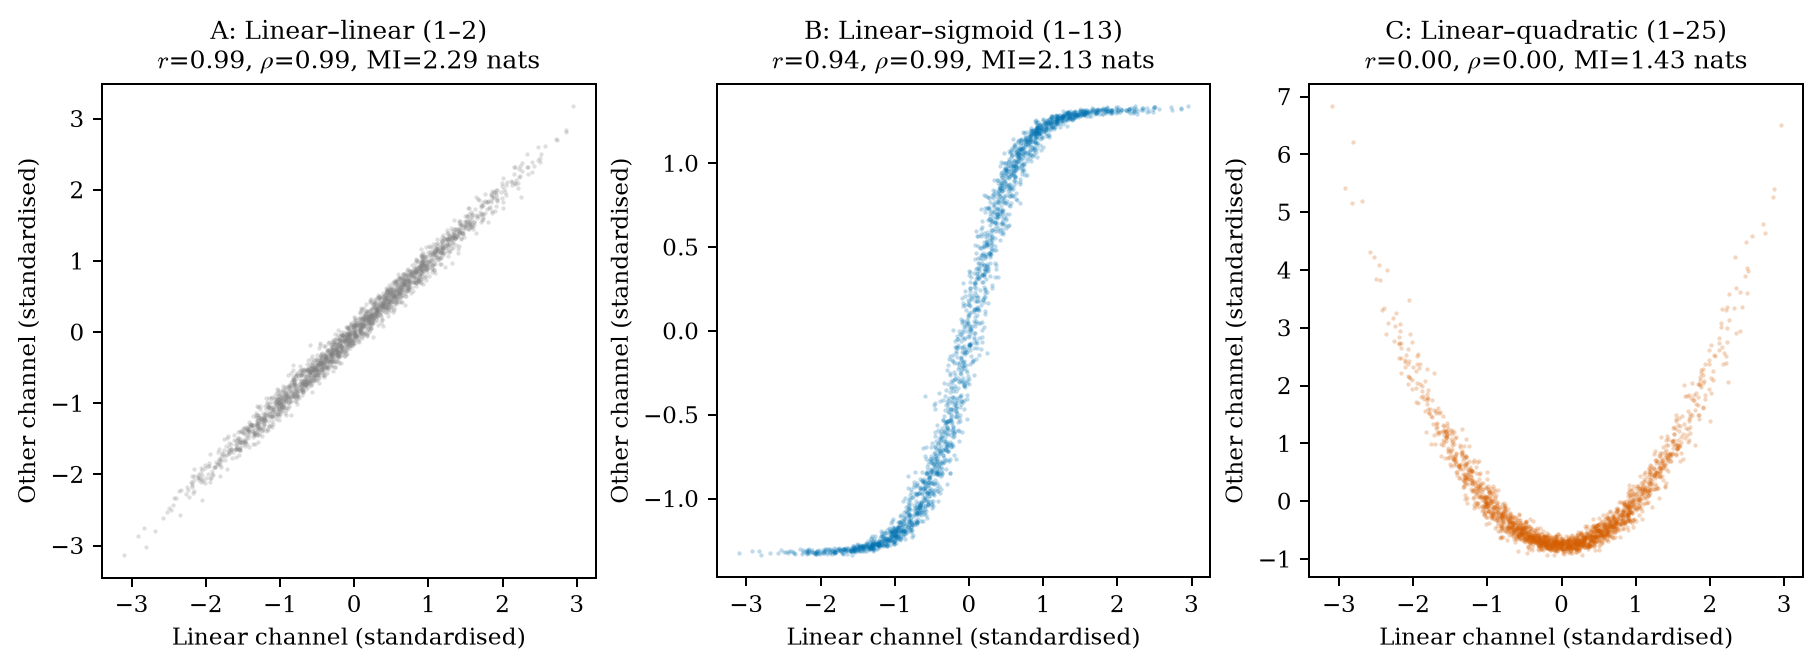

In [3]:
fig = plot_rmi_channel_pairs(frame, OUT, label_edges=True, beta_tag=BETA_TAG)
plt.show()

For each recording, $z_{ab}=\mathrm{corr}_{i<j}(A^{(a)}_{ij},A^{(b)}_{ij})$. This measures linear agreement between SPI profiles over unique unordered channel pairs. Channel pairs within one recording are dependent; the independent replication unit is the MTS instance. Constant profiles have undefined $z$. MI is KSG with $k=4$, in nats throughout; no Linfoot transform enters $z$. For bivariate Gaussian pairs, $\mathrm{MI}=-\tfrac12\log(1-r^2)$, so even the linear baseline need not have $z_{r,\mathrm{MI}}=1$.

These SPI–SPI planes use predetermined instance 0 at $\beta=\pi$. Grey marks same-family pairs; colours mark L–M, L–Q and M–Q. Each point is one channel pair and each annotation uses all pairs. Independent axis limits reveal the structure; visual slopes across different panels are not comparable.

The matrix heatmaps retain channel order and mark the same family boundaries. The r/rho scales are shared (−1 to 1); MI has its own nats scale. Blank diagonals are self-pairs excluded from z. In the following SPI planes, A/B/C refer to the third row, the same mixed recording inspected above.

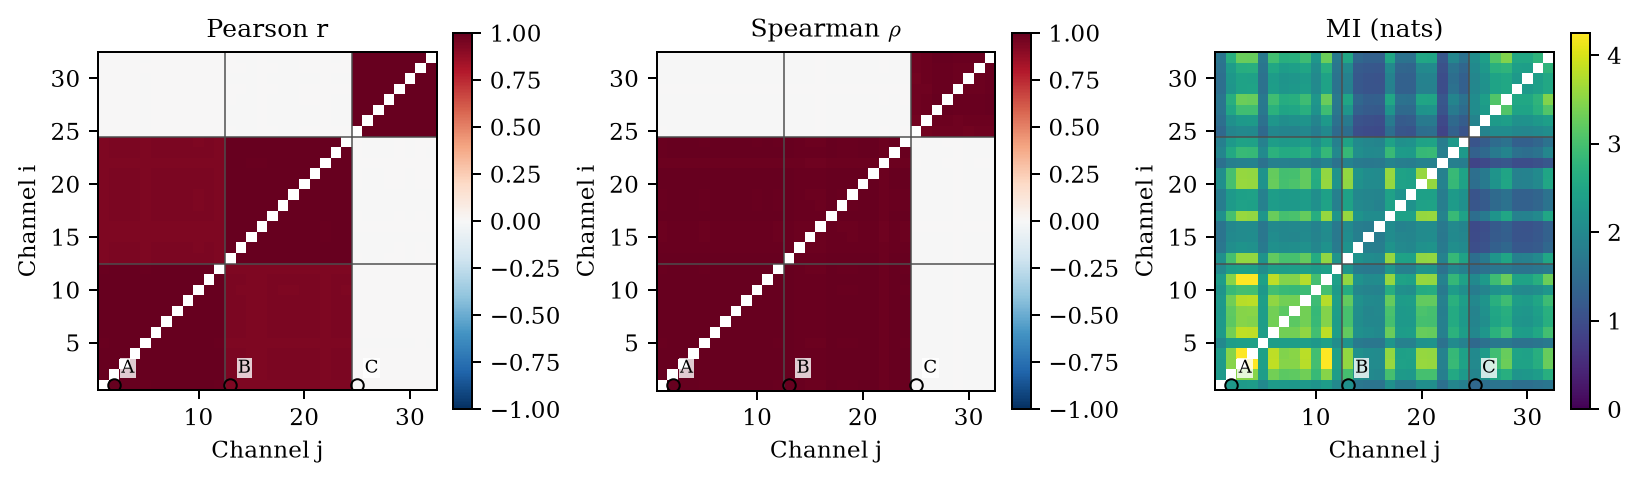

In [4]:
fig = plot_rmi_matrices(frame, OUT, beta_tag=BETA_TAG)
plt.show()

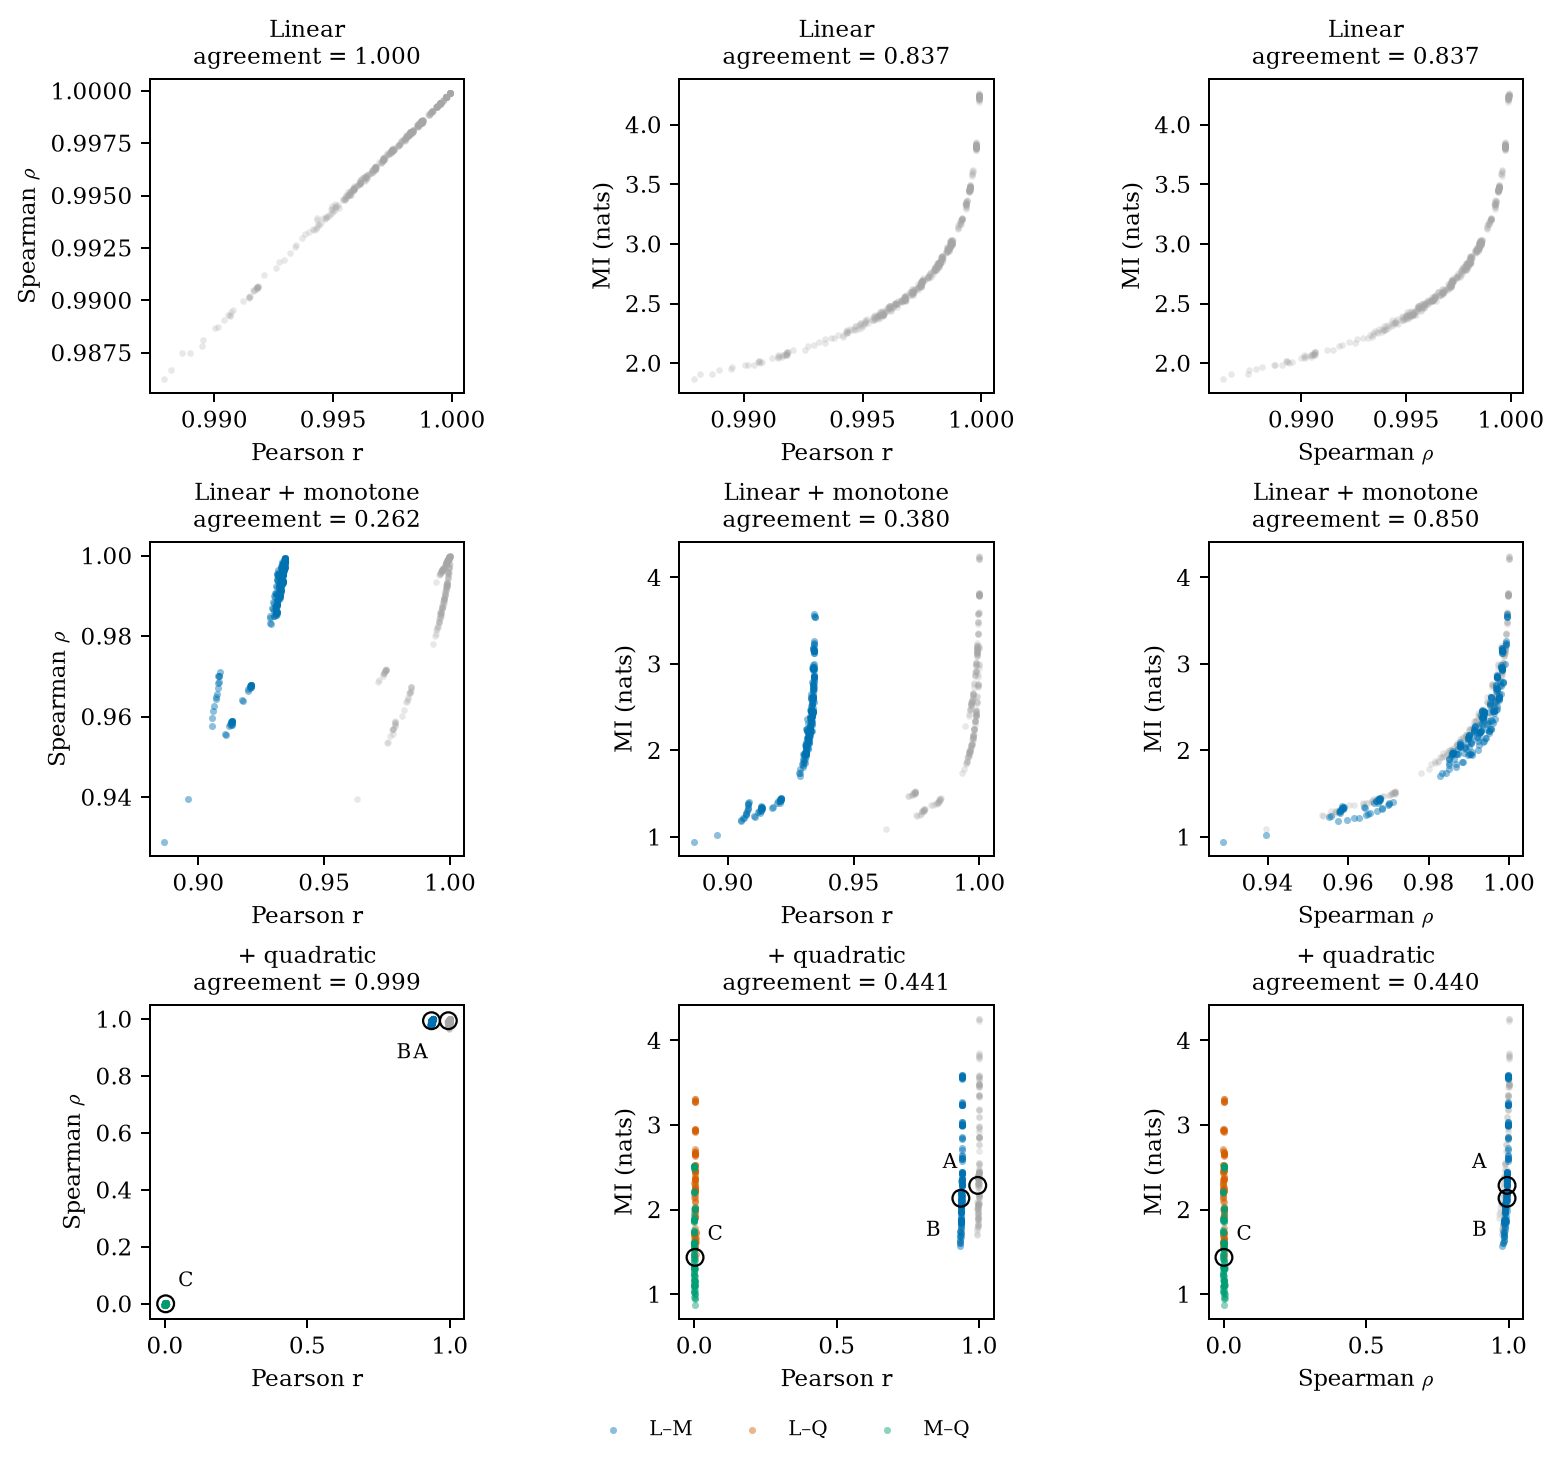

In [5]:
fig = plot_spi_planes(frame, 'r-rho-mi', OUT, highlight_edges=True, beta_tag=BETA_TAG)
plt.show()

Rainclouds show 50 independent recordings per construction, with descriptive densities and median bars. Each panel is one SPI pair; its y-scale is shared across the three constructions. Compare numerical ticks when reading different panels.

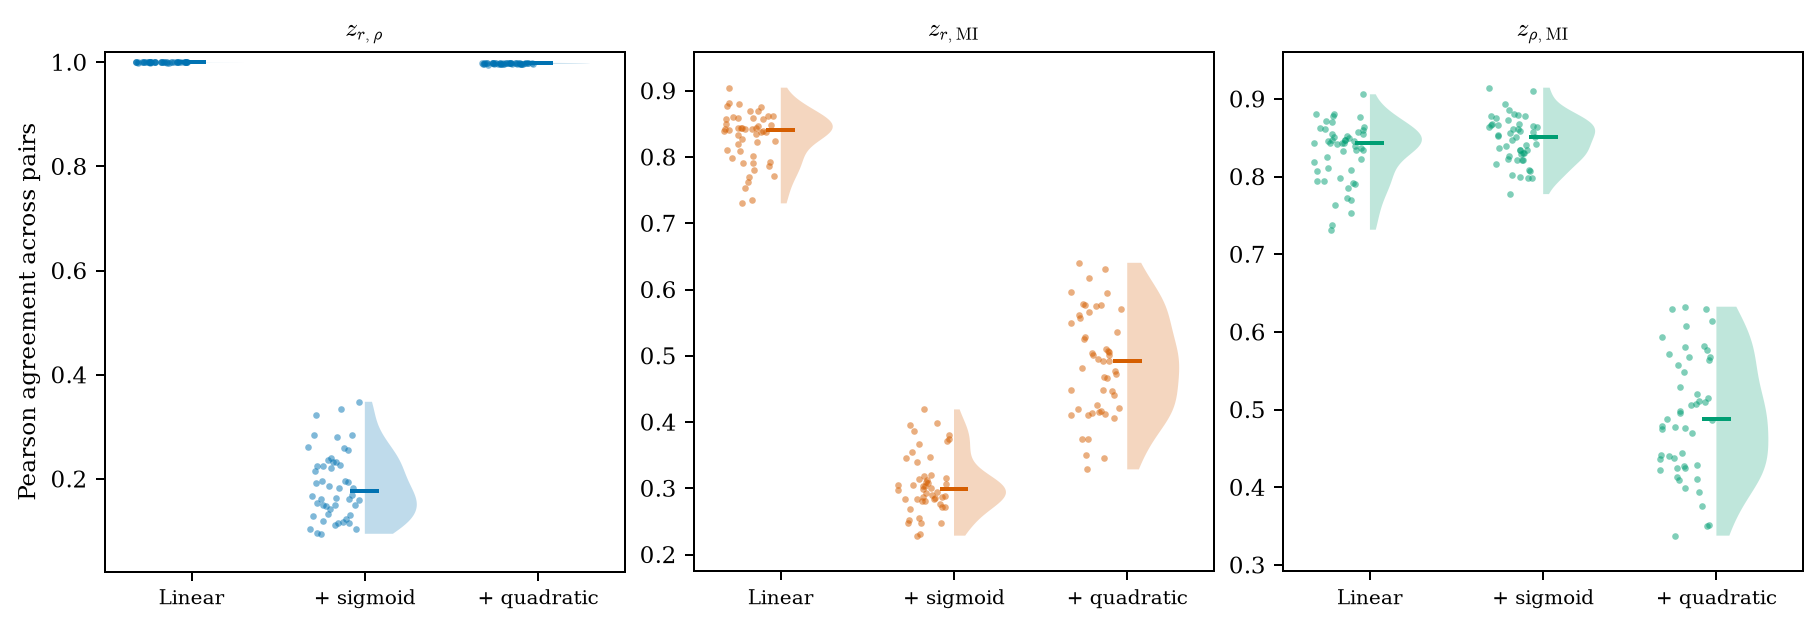

In [6]:
fig = plot_pair_rainclouds(frame, OUT, beta_tag=BETA_TAG)
plt.show()

At this fixed beta, mean r–rho agreement is 0.9998 for linear channels, 0.1878 after introducing sigmoid channels, and 0.9978 in the mixture containing quadratic channels. The construction therefore breaks and restores the profile agreement. The next step identifies why the restoration occurs, rather than attributing it simply to both statistics missing the folded relationships.

Why does r–rho agreement return near one after adding quadratic channels? Decompose the empirical covariance over pair types $G\in\{LL,LM,LQ,MM,MQ,QQ\}$:

$$z_{r,\rho}=\frac{\sum_g p_g\,\mathrm{Cov}(r,\rho\mid g)}{s_r s_\rho}+\frac{\mathrm{Cov}_g(\bar r_g,\bar\rho_g)}{s_r s_\rho}.$$

The second covariance weights group centroids by their pair proportions $p_g$. This is an exact decomposition of the same z, not a new estimator or an independence assumption. Means and pointwise 95% Student-t intervals below use 50 MTS instances per mixture at $\beta=\pi$. The components add to the total for every recording; the analysis checks that identity numerically.

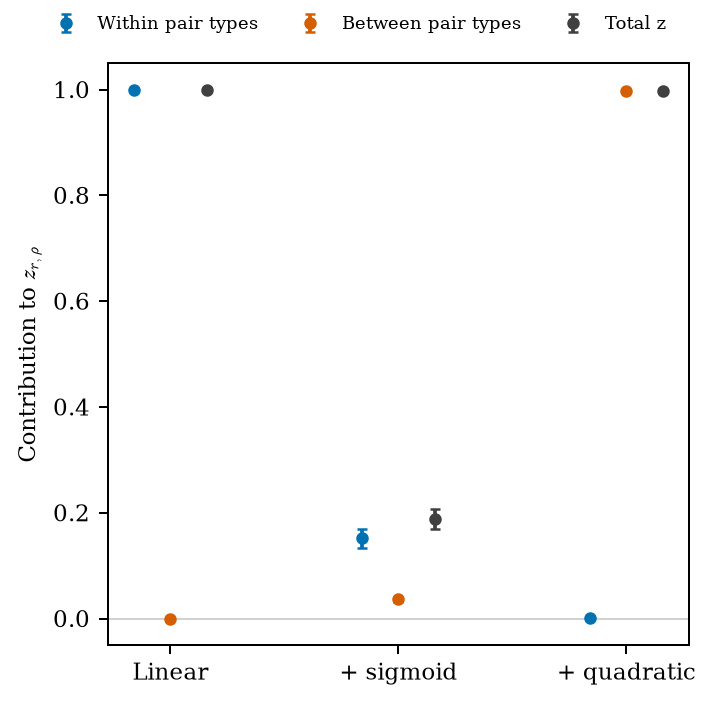

In [7]:
composition = analyze_rmi_composition(frame, OUT, beta_tag=BETA_TAG)
fig = plot_rmi_composition(composition, OUT)
plt.show()

In the L/M/Q recordings, the mean within-type contribution is 0.00016 and the between-type contribution is 0.99758, giving total z≈0.99775. Thus renewed agreement overwhelmingly reflects differences between pair-family centroids: both statistics divide folded and unfolded relationships into similar broad groups. It does not establish close agreement within every pair type. In the L/M mixture the contributions are 0.15139 and 0.03640, summing to 0.18779. These values describe the fixed-beta construction, including its noise and pair proportions.

Supporting serial-dependence check on these same 150 recordings: the AUTO temporal-exclusion KSG variant changes r–MI and rho–MI agreement by median absolute amounts 0.00101 and 0.00035; the maximum is 0.01005. The qualitative pattern remains. Ordinary KSG ($k=4$) is primary; this sensitivity is not a proof of unbiased estimation. [KSG reference](https://arxiv.org/abs/cond-mat/0305641).

Generation settings remain in `research/cases/r_rho_mi/configs/260924_beta.yaml`; only its beta-pi variants and all-linear baseline are selected here. Figures and selected-input/decomposition CSVs are saved in `results/cases/r-rho-mi-261016/`.